In [2]:
import pandas as pd

df = pd.read_csv("spam.csv", encoding="latin-1")
df = df[["v1", "v2"]]
df.columns = ["label", "message"]

print(df.shape)
print(df["label"].value_counts())
df.head()

(5572, 2)
label
ham     4825
spam     747
Name: count, dtype: int64


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [14]:
print("Missing values:")
print(df.isnull().sum())
print("Duplicate messages:", df.duplicated(subset="message").sum())

df = df.drop_duplicates(subset="message").reset_index(drop=True)
print("Messages after removing duplicates:", len(df))

Missing values:
label      0
message    0
clean      0
target     0
dtype: int64
Duplicate messages: 403
Messages after removing duplicates: 5169


In [4]:
import re

def clean_text(text):
    text = text.lower()
    text = re.sub(r"[^a-z\s]", "", text)
    return text

df["clean"] = df["message"].apply(clean_text)
df["target"] = df["label"].map({"ham": 0, "spam": 1})

df.head()

,label,message,clean,target
0,ham,"Go until jurong point, crazy.. Available only ...",go until jurong point crazy available only in ...,0
1,ham,Ok lar... Joking wif u oni...,ok lar joking wif u oni,0
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,free entry in a wkly comp to win fa cup final...,1
3,ham,U dun say so early hor... U c already then say...,u dun say so early hor u c already then say,0
4,ham,"Nah I don't think he goes to usf, he lives aro...",nah i dont think he goes to usf he lives aroun...,0


In [5]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    df["clean"], df["target"],
    test_size=0.2, random_state=42, stratify=df["target"]
)

print("Training messages:", len(X_train))
print("Testing messages:", len(X_test))

Training messages: 4457
Testing messages: 1115


In [6]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(stop_words="english")
X_train_vec = tfidf.fit_transform(X_train)
X_test_vec = tfidf.transform(X_test)

print("Training matrix shape:", X_train_vec.shape)
print("Testing matrix shape:", X_test_vec.shape)

Training matrix shape: (4457, 7274)
Testing matrix shape: (1115, 7274)


In [15]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, StratifiedKFold

pipe = Pipeline([
    ("tfidf", TfidfVectorizer(stop_words="english")),
    ("model", MultinomialNB())
])

param_grid = {
    "model__alpha": [0.01, 0.1, 0.5, 1.0, 2.0],
    "tfidf__ngram_range": [(1, 1), (1, 2)]
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
grid = GridSearchCV(pipe, param_grid, cv=cv, scoring="f1", n_jobs=-1)
grid.fit(X_train, y_train)

print("Best hyperparameters:", grid.best_params_)
print("Best cross-validation F1:", round(grid.best_score_, 4))

best_model = grid.best_estimator_
y_pred = best_model.predict(X_test)

Best hyperparameters: {'model__alpha': 0.1, 'tfidf__ngram_range': (1, 2)}
Best cross-validation F1: 0.9412


In [9]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, classification_report

y_pred = model.predict(X_test_vec)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred), 4))
print("Recall:", round(recall_score(y_test, y_pred), 4))
print()
print(classification_report(y_test, y_pred, target_names=["Ham", "Spam"]))

Accuracy: 0.9623
Precision: 0.9908
Recall: 0.7248

              precision    recall  f1-score   support

         Ham       0.96      1.00      0.98       966
        Spam       0.99      0.72      0.84       149

    accuracy                           0.96      1115
   macro avg       0.98      0.86      0.91      1115
weighted avg       0.96      0.96      0.96      1115



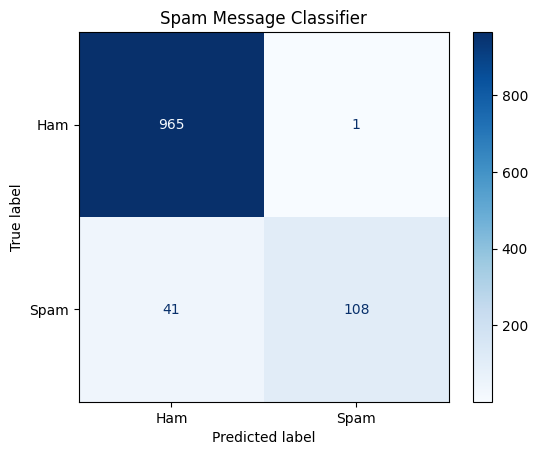

In [10]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=["Ham", "Spam"], cmap="Blues"
)
plt.title("Spam Message Classifier")
plt.show()

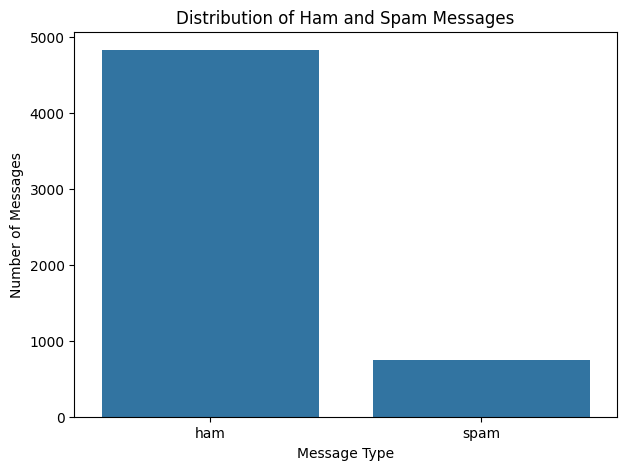

In [11]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="label")
plt.title("Distribution of Ham and Spam Messages")
plt.xlabel("Message Type")
plt.ylabel("Number of Messages")
plt.show()

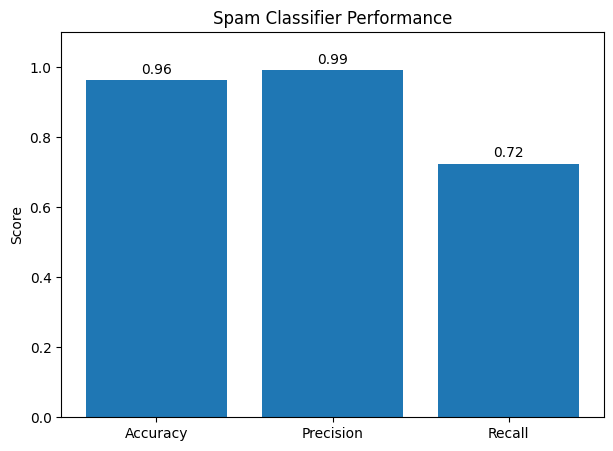

In [12]:
from sklearn.metrics import accuracy_score, precision_score, recall_score

scores = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred),
    "Recall": recall_score(y_test, y_pred)
}

plt.figure(figsize=(7, 5))
plt.bar(scores.keys(), scores.values())
plt.ylim(0, 1.1)
plt.title("Spam Classifier Performance")
plt.ylabel("Score")
for i, v in enumerate(scores.values()):
    plt.text(i, v + 0.02, f"{v:.2f}", ha="center")
plt.show()

In [13]:
samples = [
    "Congratulations! You won a free prize. Call now to claim",
    "Hey, are we meeting at the library tomorrow?"
]
print(model.predict(tfidf.transform([clean_text(s) for s in samples])))

[1 0]
